In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

from data_loading import data_loading, files
df = data_loading(files['final_df'])

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 513801 entries, 0 to 513800
Data columns (total 51 columns):
 #   Column                                             Non-Null Count   Dtype         
---  ------                                             --------------   -----         
 0   collision_index                                    513801 non-null  object        
 1   collision_severity                                 513801 non-null  int64         
 2   date                                               513801 non-null  datetime64[ns]
 3   day_of_week                                        513801 non-null  int64         
 4   time                                               513801 non-null  object        
 5   latitude                                           513748 non-null  float64       
 6   longitude                                          513748 non-null  float64       
 7   urban_or_rural_area                                513793 non-null  float64       
 8   spee

#**Exploratary Data Anyalysis**


##**Accident Severity Analysis**

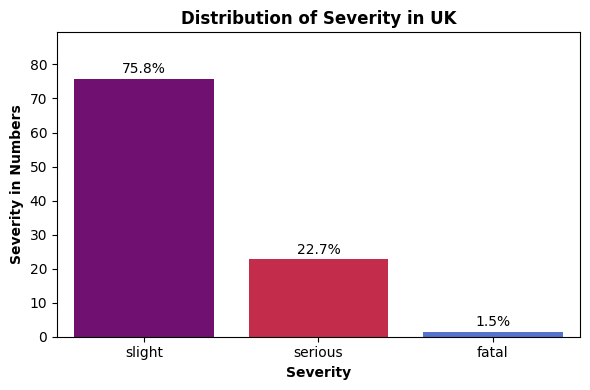

In [49]:
# Distribution of Fatal, Serious and Slight accidents:

order = ['fatal', 'slight', 'serious']

dist = (
    df['collision_severity_label']
    .value_counts()
    .reindex(order)
    .rename('count')
    .reset_index()
    .rename(columns={'index': 'severity', 'collision_severity_label': 'severity'})
)
dist['percent'] = ((dist['count'] / dist['count'].sum()) * 100).round(2)
dist = dist.sort_values('count', ascending=False)

# plot
fig, ax = plt.subplots(figsize=(6,4))
colors = {
    'fatal': 'royalblue',
    'slight': 'purple',
    'serious': 'crimson'
}
sns.barplot(
    data=dist,
    x='severity',
    y='percent',
    hue='severity',
    palette=colors,
    ax=ax
)

for c in ax.containers:
  ax.bar_label(c, fmt=f"%1.1f%%", padding=2)


ax.set_ylim(0, dist['percent'].max() * 1.18)
ax.set_title("Distribution of Severity in UK", fontweight='bold')
ax.set_xlabel("Severity", fontweight='semibold')
ax.set_ylabel("Severity in Numbers", fontweight='semibold')
plt.tight_layout()
plt.show()

##**Rural vs Urban severity comparison.**

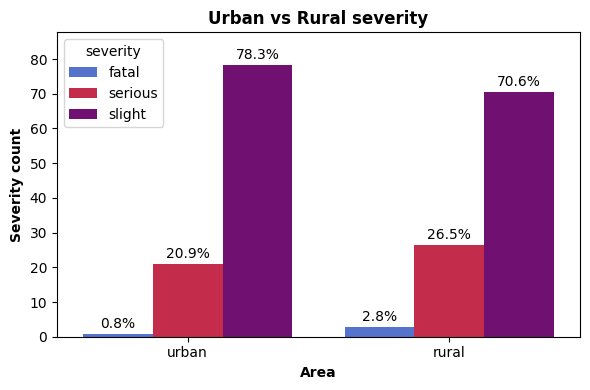

    area severity   count    pct
0  urban    fatal    2779   0.80
1  rural    fatal    4773   2.83
2  urban  serious   72112  20.88
3  rural  serious   44684  26.53
4  urban   slight  270423  78.31
5  rural   slight  118972  70.64


In [46]:
# Rural vs Urban severity comparison.

severity = ['fatal', 'serious', 'slight']
area = ['urban', 'rural']

severity_area = df[
    df['collision_severity_label'].isin(severity) &
    df['urban_or_rural_area_label'].isin(area)
].copy()

# cross table
sev_result = pd.crosstab(
    severity_area['urban_or_rural_area_label'].rename('area'),
    severity_area['collision_severity_label'].rename('severity')
)[['fatal', 'serious', 'slight']].reindex(['urban', 'rural'])



plot_df = sev_result.reset_index().melt(id_vars='area',
                                        var_name='severity',
                                        value_name='count')

plot_df['pct'] = (plot_df['count'] / plot_df.groupby('area')['count'].transform('sum') * 100).round(2)

# barplot
fig, ax = plt.subplots(figsize=(6,4))
sns.barplot(
    data=plot_df,
    x='area',
    y='pct',
    hue='severity',
    palette=colors,
    ax=ax
)

# pct label
for c in ax.containers:
  ax.bar_label(c, fmt=f"%1.1f%%", padding=2)


ax.set_ylim(0, plot_df['pct'].max() * 1.12)
ax.set_title("Urban vs Rural severity", fontweight='bold')
ax.set_xlabel("Area", fontweight='semibold')
ax.set_ylabel("Severity count", fontweight='semibold')
plt.tight_layout()
plt.show()


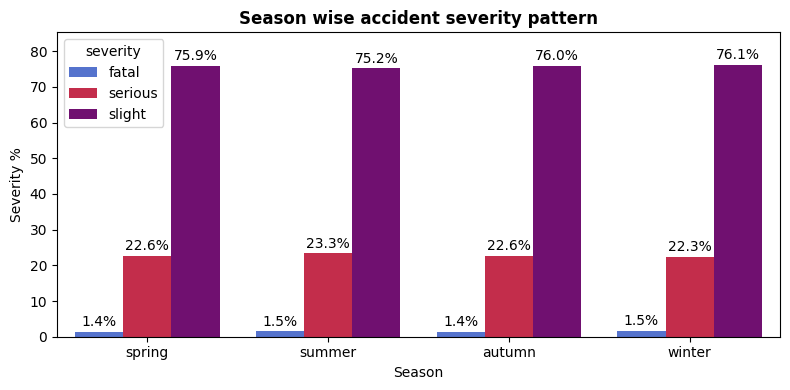

In [78]:

# Summer vs Winter Accident pattern


# season mapping
season_map = {
    3: "spring", 4: "spring", 5: "spring",
    6: "summer", 7: "summer", 8: "summer",
    9: "autumn", 10: "autumn", 11: "autumn",
    12: "winter", 1: "winter", 2: "winter"

}
df['season'] = df['month'].map(season_map)

# severity-season

severity = ['fatal', 'serious', 'slight']
season_severity = df[
    df['collision_severity_label'].isin(severity) &
    df['season']
]
season_result = pd.crosstab(
    season_severity['season'],
    season_severity['collision_severity_label'].rename('severity')
    )[['fatal', 'serious', 'slight']].reindex(['spring', 'summer', 'autumn', 'winter'])

season_plot = season_result.reset_index().melt(id_vars='season',
                                               var_name='severity',
                                               value_name='count')

season_plot['percent'] = (season_plot['count'] / season_plot.groupby('season')['count'].transform('sum') * 100).round(2)

# ploting
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(
    data=season_plot,
    x='season',
    y='percent',
    hue='severity',
    palette=colors,
    ax=ax
)

for c in ax.containers:
  ax.bar_label(c, fmt=f"%1.1f%%", padding=2)

ax.set_title("Season wise accident severity pattern", fontweight='bold')
ax.set_xlabel("Season")
ax.set_ylabel("Severity %")
ax.set_ylim(0, season_plot['percent'].max() * 1.12)
plt.tight_layout()
plt.show()

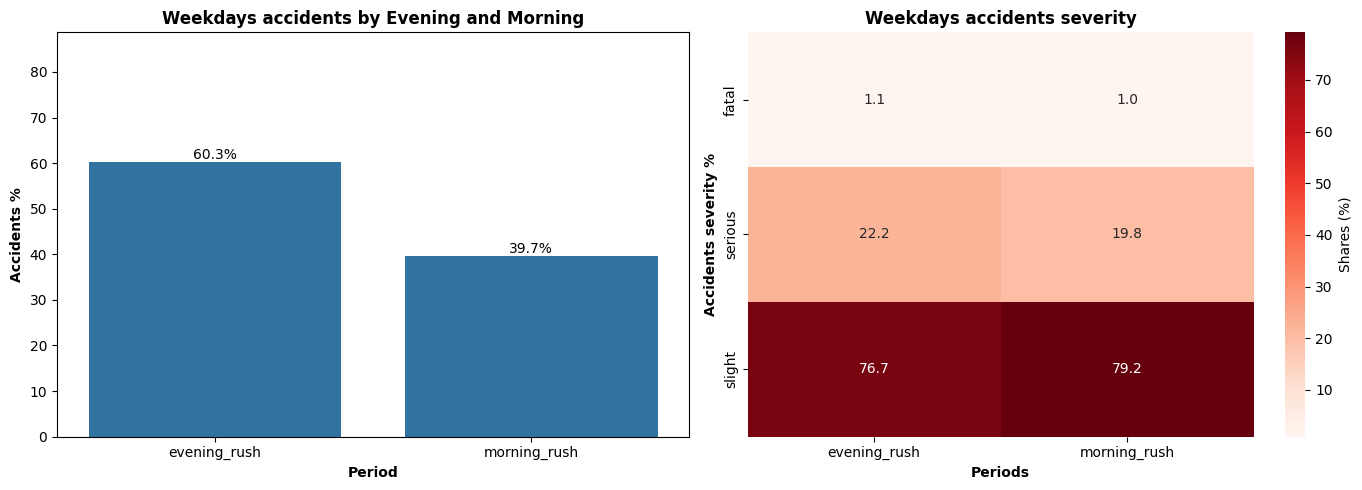

In [129]:
# Morning rush hour vs evening rush hour?
df['hours'] = pd.to_datetime(df['time'], format="%H:%M", errors='coerce').dt.hour


weekdays = df[df['day_of_week'].isin([1, 2, 3, 4, 5])]

conditions = [
    weekdays['hours'].between(7, 9),
    weekdays['hours'].between(16, 18)
]
choices = ['morning_rush', 'evening_rush']

weekdays = weekdays.assign(period=np.select(conditions, choices, default='others'))
rush = weekdays[weekdays['period'] != 'others']

counts = rush.groupby(['period', 'collision_severity_label']).size().reset_index(name='count')

counts['percent'] = (counts['count'] / counts.groupby('period')['count'].transform('sum') * 100).round(2)
pivot = counts.pivot(index='collision_severity_label', columns='period', values='percent')

# Overall Accidents:
acc_rush = rush.groupby('period')['collision_index'].size().reset_index(name='count')
acc_rush['percent'] = (acc_rush['count'] / acc_rush['count'].sum() * 100).round(2)



# Plot-

fig, axes = plt.subplots(1, 2, figsize=(14,5))
# Accidentd overall
sns.barplot(
    data=acc_rush,
    x='period',
    y='percent',
    ax=axes[0]
)
# accidents overall
sns.heatmap(
    pivot,
    annot=True,
    fmt='.1f',
    cbar_kws={'label': 'Shares (%)'},
    cmap='Reds',
    ax=axes[1]
)
# Adding more details-

for c in axes[0].containers:
  axes[0].bar_label(c, fmt='%1.1f%%')
axes[0].set_ylim(0, counts['percent'].max() * 1.12)
axes[0].set_title("Weekdays accidents by Evening and Morning", fontweight='bold')
axes[0].set_xlabel("Period", fontweight='semibold')
axes[0].set_ylabel("Accidents %", fontweight='semibold')

axes[1].set_title("Weekdays accidents severity", fontweight='bold')
axes[1].set_xlabel("Periods", fontweight='semibold')
axes[1].set_ylabel("Accidents severity %", fontweight='semibold')

plt.tight_layout()
plt.show()
